# **Run 8: ViT-L/16 (SWAG), linear probe then careful fine-tuning (target: 99%+)**
- **Run 5** (full fine-tune of ViT-B/16, random head, lr 5e-5 for every layer): 97.80%. The random head sent large gradients
  into the pretrained layers, so test accuracy dropped to 78.8% after epoch 1 and the model overfit.
- **Run 6** (frozen ViT-L/16 features + linear classifier): 98.05%, flat from epoch 9. That's the limit of the frozen features.

This run combines the two the standard way (*LP-FT*, linear probing then fine-tuning):
1. **Stage 1, linear probe:** the backbone is frozen and only the new 10-class head is trained. Afterwards the head already gives
   sensible predictions (about 98%), so the gradients reaching the backbone in stage 2 are small and don't distort the
   pretrained features.
2. **Stage 2, fine-tune everything** with a small learning rate and **layer-wise LR decay**: the top transformer block gets the
   full LR, and each block below it gets 0.8x the LR of the block above. Early layers hold generic features (edges, textures),
   so they barely change; later layers adapt to CIFAR-10.

**Memory:** fine-tuning ViT-L needs about 8 GB of GPU memory. **Shut down other notebook kernels first** (e.g. Run 6 keeps its
model and features on the GPU until its kernel is closed). The first run of this notebook crashed with CUDA out-of-memory for
that reason.

In [1]:
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   # less fragmentation; must be set before torch
import gc
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import vit_l_16, ViT_L_16_Weights
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
torch.backends.cuda.matmul.allow_tf32 = True
print(device, torch.cuda.get_device_name(0) if device == "cuda" else "")
free, total = torch.cuda.mem_get_info()
print(f"GPU memory free: {free / 2**30:.1f} / {total / 2**30:.1f} GiB")
if free < 10 * 2**30:
    print("WARNING: less than 10 GiB free. Close other notebook kernels / GPU apps, or stage 2 may run out of memory.")

c:\Users\Admin\Documents\GitHub\DL-Assignment2-CNN-CIFAR\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cuda NVIDIA GeForce RTX 4080 SUPER
GPU memory free: 14.7 / 16.0 GiB


# **Data**

In [2]:
IMG_SIZE = 224
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

# light augmentation at 32x32 on the CPU; upscaling + normalization on the GPU
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4, padding_mode="reflect"),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])

train_dataset = datasets.CIFAR10(root="../dataset", train=True, download=True, transform=train_transform)
test_dataset = datasets.CIFAR10(root="../dataset", train=False, download=True, transform=transforms.ToTensor())

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4,
                          pin_memory=True, persistent_workers=True, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, num_workers=4,
                         pin_memory=True, persistent_workers=True)
classes = train_dataset.classes

def to_model_input(images):
    """32x32 [0,1] batch on GPU -> 224x224 ImageNet-normalized batch"""
    images = F.interpolate(images, size=IMG_SIZE, mode="bicubic", align_corners=False).clamp(0, 1)
    return (images - IMAGENET_MEAN) / IMAGENET_STD

print(f"Train length: {len(train_dataset)}\nTest length: {len(test_dataset)}\nClasses: {classes}")

Train length: 50000
Test length: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


# **Model: pretrained ViT-L/16 SWAG with a new 10-class head**

In [3]:
model = vit_l_16(weights=ViT_L_16_Weights.IMAGENET1K_SWAG_LINEAR_V1)    # downloads ~1.2GB once
model.heads.head = nn.Linear(model.heads.head.in_features, 10)          # 1024 -> 10 classes
nn.init.zeros_(model.heads.head.weight)
nn.init.zeros_(model.heads.head.bias)
model = model.to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.0f}M")

Parameters: 303M


# **Training and Evaluation**

In [4]:
AMP_DTYPE = torch.bfloat16
ACCUM_CHUNKS = 2        # each batch of 32 is processed as 2 chunks of 16 (gradient accumulation) to halve activation memory
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

def train_one_epoch(model, loader, optimizer, scheduler, params):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in tqdm(loader, desc="Training", leave=False):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        for img_chunk, lbl_chunk in zip(images.chunk(ACCUM_CHUNKS), labels.chunk(ACCUM_CHUNKS)):
            with torch.autocast(device_type="cuda", dtype=AMP_DTYPE):
                outputs = model(to_model_input(img_chunk))
                loss = criterion(outputs, lbl_chunk)
            (loss * lbl_chunk.size(0) / labels.size(0)).backward()   # same gradient as one full batch
            total_loss += loss.item() * lbl_chunk.size(0)
            correct += (outputs.argmax(1) == lbl_chunk).sum().item()
        nn.utils.clip_grad_norm_(params, 1.0)
        optimizer.step()
        scheduler.step()
        total += labels.size(0)
    return total_loss / total, correct / total

def evaluate(model, loader, tta=True, return_preds=False):
    model.eval()
    total_loss, correct, total, all_preds = 0, 0, 0, []
    with torch.no_grad():
        for images, labels in loader:
            images = to_model_input(images.to(device, non_blocking=True))
            labels = labels.to(device, non_blocking=True)
            with torch.autocast(device_type="cuda", dtype=AMP_DTYPE):
                outputs = model(images)
                if tta:                                 # average with horizontally flipped images
                    outputs = (outputs + model(torch.flip(images, dims=[3]))) / 2
                loss = criterion(outputs.float(), labels)
            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
            all_preds.append(outputs.argmax(1).cpu())
    if return_preds:
        return total_loss / total, correct / total, torch.cat(all_preds)
    return total_loss / total, correct / total

history = {"stage": [], "train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

def log_epoch(stage, epoch, epochs, tr_loss, tr_acc, te_loss, te_acc):
    for k, v in zip(history, (stage, tr_loss, tr_acc, te_loss, te_acc)):
        history[k].append(v)
    print(f"[{stage}] Epoch {epoch}/{epochs} | train loss {tr_loss:.4f} | train acc {tr_acc:.4f} | "
          f"test loss {te_loss:.4f} | test acc {te_acc:.4f}")

# **Stage 1: linear probe (backbone frozen, train only the head)**

In [5]:
LP_EPOCHS = 1
for p in model.parameters():
    p.requires_grad = False
head_params = list(model.heads.parameters())
for p in head_params:
    p.requires_grad = True

optimizer = optim.AdamW(head_params, lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=1e-3, epochs=LP_EPOCHS,
                                          steps_per_epoch=len(train_loader), pct_start=0.1)
for epoch in range(LP_EPOCHS):
    tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, scheduler, head_params)
    te_loss, te_acc = evaluate(model, test_loader)
    log_epoch("probe", epoch + 1, LP_EPOCHS, tr_loss, tr_acc, te_loss, te_acc)

[probe] Epoch 1/1 | train loss 0.6904 | train acc 0.9552 | test loss 0.5879 | test acc 0.9779


# **Stage 2: fine-tune everything with layer-wise LR decay**

In [6]:
FT_EPOCHS = 5
BASE_LR = 2e-5          # LR of the head and the top transformer block
LAYER_DECAY = 0.8       # each block below gets 0.8x the LR of the block above

del optimizer, scheduler                                   # free stage-1 state before the big optimizer is created
gc.collect()
torch.cuda.empty_cache()

for p in model.parameters():
    p.requires_grad = True

num_layers = len(model.encoder.layers)                     # 24 for ViT-L
def layer_id(name):
    if name.startswith(("conv_proj", "class_token", "encoder.pos_embedding")):
        return 0                                           # patch embedding: lowest LR
    if name.startswith("encoder.layers."):
        return int(name.split(".")[2].split("_")[-1]) + 1  # encoder_layer_i -> i + 1
    return num_layers + 1                                  # final LayerNorm + head: full LR

groups = {}
for name, p in model.named_parameters():
    lid = layer_id(name)
    no_wd = p.ndim == 1 or name in ("class_token", "encoder.pos_embedding")
    key = (lid, no_wd)
    if key not in groups:
        groups[key] = {"params": [], "lr": BASE_LR * LAYER_DECAY ** (num_layers + 1 - lid),
                       "weight_decay": 0.0 if no_wd else 0.05}
    groups[key]["params"].append(p)
param_groups = list(groups.values())
print(f"LR range: {min(g['lr'] for g in param_groups):.2e} (patch embedding) to {BASE_LR:.0e} (head)")

all_params = list(model.parameters())
optimizer = optim.AdamW(param_groups)
scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=[g["lr"] for g in param_groups], epochs=FT_EPOCHS,
                                          steps_per_epoch=len(train_loader), pct_start=0.1)
for epoch in range(FT_EPOCHS):
    tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, scheduler, all_params)
    te_loss, te_acc = evaluate(model, test_loader)
    log_epoch("finetune", epoch + 1, FT_EPOCHS, tr_loss, tr_acc, te_loss, te_acc)

torch.save(model.state_dict(), "vitl16_lpft_cifar10.pth")

LR range: 7.56e-08 (patch embedding) to 2e-05 (head)


[finetune] Epoch 1/5 | train loss 0.5536 | train acc 0.9823 | test loss 0.5302 | test acc 0.9893


[finetune] Epoch 2/5 | train loss 0.5258 | train acc 0.9912 | test loss 0.5251 | test acc 0.9910


[finetune] Epoch 3/5 | train loss 0.5143 | train acc 0.9952 | test loss 0.5239 | test acc 0.9920


[finetune] Epoch 4/5 | train loss 0.5070 | train acc 0.9977 | test loss 0.5215 | test acc 0.9931


[finetune] Epoch 5/5 | train loss 0.5039 | train acc 0.9987 | test loss 0.5221 | test acc 0.9931


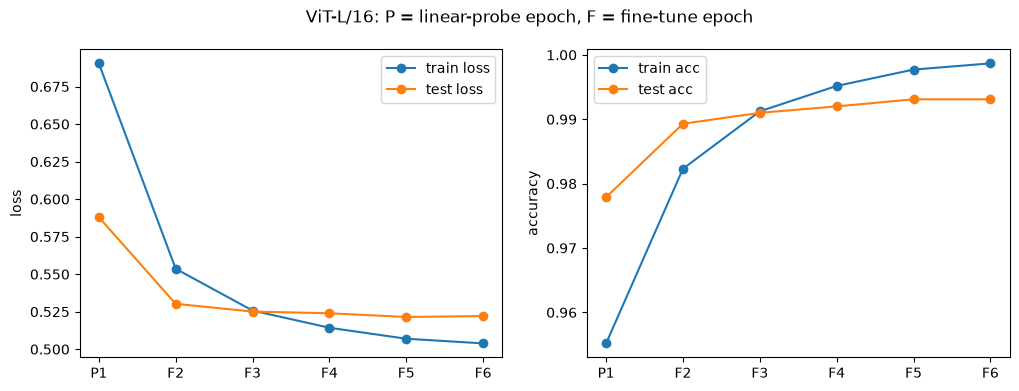

In [7]:
steps = range(1, len(history["test_acc"]) + 1)
labels = [f"{s[0].upper()}{i}" for i, s in enumerate(history["stage"], 1)]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(steps, history["train_loss"], "o-", label="train loss"); ax1.plot(steps, history["test_loss"], "o-", label="test loss")
ax1.set_xticks(list(steps), labels); ax1.set_ylabel("loss"); ax1.legend()
ax2.plot(steps, history["train_acc"], "o-", label="train acc"); ax2.plot(steps, history["test_acc"], "o-", label="test acc")
ax2.set_xticks(list(steps), labels); ax2.set_ylabel("accuracy"); ax2.legend()
fig.suptitle("ViT-L/16: P = linear-probe epoch, F = fine-tune epoch")
plt.show()

# **Final Results**

In [8]:
_, acc_plain = evaluate(model, test_loader, tta=False)
_, acc_tta, preds = evaluate(model, test_loader, tta=True, return_preds=True)
print(f"Test accuracy without TTA: {acc_plain:.4f}")
print(f"Test accuracy with flip TTA: {acc_tta:.4f}")

# per-class accuracy
test_labels = torch.tensor(test_dataset.targets)
for c, name in enumerate(classes):
    mask = test_labels == c
    print(f"{name:>10}: {(preds[mask] == c).float().mean().item():.4f}")

Test accuracy without TTA: 0.9930
Test accuracy with flip TTA: 0.9931
  airplane: 0.9950
automobile: 0.9960
      bird: 0.9940
       cat: 0.9850
      deer: 0.9930
       dog: 0.9840
      frog: 0.9980
     horse: 0.9980
      ship: 0.9980
     truck: 0.9900
